# Fine-tuning

Fine-tunes the model used by arms 3, 4 and 5 in `notebooks/04_arms.ipynb`.

**Model: Qwen3-8B.** The untuned baselines are already measured on it, it is the cheapest option,
and a seven-model probe found nothing reliably better: the whole spread across 4B to 397B sat
inside the noise, and the 27B tied the 4B.

**LoRA fine-tuning.** The base model stays frozen and small trainable matrices are added
alongside it. The task is a correction to an 8-billion-parameter model,
which is what makes a run of this size affordable.

**Scope.** The fine-tune is measured against *the same model before training*, on the same
molecules, prompt, decoder and k, computed in section 2. The untuned arms in notebook 04 are
test-set numbers under a different prompt and a larger sampling budget, so they are not comparable.
Dev scores run above test scores because a split that separates exact molecules still leaves close
analogues on both sides.

The gates in sections 1 to 3 stop a broken run before the training in section 4.

## 1. The data, and exactly what the model sees

In [1]:
import datetime as dt
import json, os, pathlib, random, sys, time
import numpy as np, pandas as pd

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
from src import evaluation as ev
from src import decoding as dec

for line in (ROOT / ".env").read_text().splitlines():
    if "=" in line and not line.startswith("#"):
        k, v = line.split("=", 1); os.environ[k.strip()] = v.strip()

import tinker
import tinker.types as tt

BASE_MODEL = "Qwen/Qwen3-8B"
train_rows = [json.loads(l) for l in (ROOT / "data/processed/train.jsonl").open()]
dev_rows   = [json.loads(l) for l in (ROOT / "data/processed/dev.jsonl").open()]
print(f"{len(train_rows):,} training examples   {len(dev_rows)} dev examples")
print()
r = train_rows[0]
print("one training example, exactly as the model receives it:")
print(f"  it is shown : {r['prompt']!r}")
print(f"  it must write: {r['completion']!r}")

TODAY = dt.date.today().isoformat()

/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_seq_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(


/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_id" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_name" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_path" has conflict with protected namespace "model_".

You may be able to resolve this warning by setting `model_config['protected_namespaces'] = ()`.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pydantic/_internal/_fields.py:161: UserWarning: Field "model_owner" has conflict with protected namespace "model_".

You may be able to res

17,075 training examples   437 dev examples

one training example, exactly as the model receives it:
  it is shown : '<parent>C1[C@@]2(C)[C@@H](CC[C@@H]2O)[C@@H]2CC[C@H]3CC(=O)CC[C@]3(C)[C@H]2C1</parent>\n<metabolite>'
  it must write: 'CC12CCC3C(CCC4CC(O)CCC43C)C1CCC2O</metabolite>'


The split between those two lines is what the model is scored on. Everything in `prompt` is
context; everything in `completion` is scored.

The parent molecule is not part of the target, so the model does not spend capacity learning to
generate drug molecules.

In [2]:
service = tinker.ServiceClient(api_key=os.environ["TINKER_API_KEY"])
training = service.create_lora_training_client(
    base_model=BASE_MODEL, rank=32,
    train_mlp=True, train_attn=True, train_unembed=True,   # all matrices
)
tokenizer = training.get_tokenizer()
print(f"LoRA client ready: {BASE_MODEL}, rank 32, all weight matrices")

EOS = tokenizer.eos_token_id or 0

def to_datum(row):
    """One training example.

    The model sees prompt and completion as one sequence, because a causal model predicts each
    token from everything before it. What makes this a *conditional* task rather than plain
    language modelling is the weights: 0 on every prompt position, 1 on every position that
    predicts an answer token. Targets are the sequence shifted left by one, since position i
    predicts token i+1.

    The last position predicts EOS and is supervised too. Leaving it at 0, which is the obvious
    way to write this line, trains the model to produce answers but never to stop. Termination
    would then rest entirely on the stop string, and a sample that fails to emit the closing tag
    runs to max_tokens and gets scored as unreadable chemistry rather than as a missing stop
    signal.
    """
    prompt_ids = tokenizer.encode(row["prompt"])
    answer_ids = tokenizer.encode(row["completion"])
    ids = prompt_ids + answer_ids
    targets = ids[1:] + [EOS]
    weights = [0.0] * (len(prompt_ids) - 1) + [1.0] * len(answer_ids) + [1.0]
    return tt.Datum(
        model_input=tt.ModelInput.from_ints(ids),
        loss_fn_inputs={"target_tokens": targets, "weights": weights},
    )

def n_supervised(rows):
    """Supervised positions across a batch: every answer token, plus one EOS position each."""
    return sum(len(tokenizer.encode(r["completion"])) + 1 for r in rows)

def batch_loss(fb_output, supervised):
    """Mean cross-entropy per supervised token.

    The denominator is passed in, not inferred by counting which returned values are non-zero.
    Counting non-zeros looks equivalent and is not. The closing tag is 5 of the 27 answer tokens
    in a typical example and is byte-identical across all 17,075 of them, so once the model
    predicts it with near certainty those losses underflow to exactly 0.0. They would then drop
    out of a non-zero denominator while their zeros stayed in the numerator, and the plotted
    curve would drift upward by roughly a fifth *because training was working* -- which is
    precisely the shape section 5 tells the reader to interpret as overfitting.
    """
    total = sum(float(np.asarray(o["elementwise_loss"].data).sum())
                for o in fb_output.loss_fn_outputs)
    return total / max(supervised, 1)

# Use forward(); forward_backward() leaves a gradient the next optim_step folds in.
_row = train_rows[0]
_el = np.asarray(training.forward([to_datum(_row)], "cross_entropy").result()
                 .loss_fn_outputs[0]["elementwise_loss"].data)
_n_prompt = len(tokenizer.encode(_row["prompt"])) - 1
assert _el[:_n_prompt].sum() == 0, "prompt positions are contributing loss; the weights are wrong"
assert _el[_n_prompt] != 0, (
    "the first answer position carries no loss, so the mask is one token late and the first "
    "answer token is never supervised. The prompt-only assertion above cannot catch this.")
assert (_el != 0).sum() <= n_supervised([_row]), "more positions scored than are supervised"
print(f"  masking verified: {_n_prompt} prompt positions contribute 0, "
      f"{(_el != 0).sum()} of {n_supervised([_row])} supervised positions contribute "
      f"{_el[_el != 0].mean():.3f} on average")

lengths = [len(tokenizer.encode(r["prompt"] + r["completion"])) for r in train_rows[:500]]
print(f"~{np.mean(lengths):.0f} tokens per example, longest in sample {max(lengths)}")
print(f"~{np.mean(lengths)*len(train_rows)/1e6:.2f}M tokens per epoch")


LoRA client ready: Qwen/Qwen3-8B, rank 32, all weight matrices


  masking verified: 59 prompt positions contribute 0, 26 of 28 supervised positions contribute 2.310 on average
~79 tokens per example, longest in sample 184
~1.35M tokens per epoch


Training on all weight matrices rather than attention only: in a same-training comparison it moved
retrosynthesis exact match from 15.9 to 32.9. The default already does this; the arguments are
spelled out so the choice is visible.

## 2. Evaluation during training

Training loss alone cannot separate learning from memorising. Recall on molecules the model has
never seen, scored as the final result will be, can. Dev is therefore evaluated by generating,
decoding through the shared decoding policy, and scoring with the harness every other arm uses.

In [3]:
DEV_SAMPLE = 60          # molecules in the probe that runs during training
DEV_SAMPLES_PER = 8      # generations each
DEV_LOSS_N = 160         # held-out examples behind the loss curve
K = 5

dev_by_parent = {}
for r in dev_rows:
    dev_by_parent.setdefault(r["parent"], set()).add(r["target"])

all_dev_parents = sorted(dev_by_parent)
rng = np.random.default_rng(0)
dev_parents = sorted(rng.choice(all_dev_parents, size=DEV_SAMPLE, replace=False))
unseen_parents = [p for p in all_dev_parents if p not in set(dev_parents)]
npairs = lambda ps: sum(len(dev_by_parent[p]) for p in ps)

print(f"dev set         : {npairs(all_dev_parents)} pairs over {len(all_dev_parents)} molecules")
print(f"selection probe : {npairs(dev_parents)} pairs over {len(dev_parents)} molecules")
print(f"never probed    : {npairs(unseen_parents)} pairs over {len(unseen_parents)} molecules")

sys.path.insert(0, str(ROOT / "utils"))
import molecule_utils as mu
random.seed(0)
SPELLINGS, TEMPERATURES = 4, (0.7, 1.0)
dev_spellings = {p: (mu.get_smiles_variants(p, n=SPELLINGS) or [p]) for p in all_dev_parents}


def _recall_on(client, parent_list, k=K, spellings=False):
    """Generate, decode through the shared policy, score.

    Two regimes, because the cheap one is affordable 18 times and the real one is not.
    ``spellings=False`` sends one spelling at one temperature: the probe used during training.
    ``spellings=True`` sends four spellings at two temperatures, which is the policy the reported
    arms use and the only regime in which the cross-spelling agreement step of
    ``src/decoding.py`` does anything at all. A checkpoint selected under the cheap regime is
    therefore selected on a slightly different quantity than the one finally reported, which is
    why the reported number is re-measured under the real one.
    """
    jobs = {}
    for p in parent_list:
        variants = dev_spellings[p] if spellings else [p]
        temps = TEMPERATURES if spellings else (0.8,)
        futures = []
        for v in variants:
            prompt = tt.ModelInput.from_ints(tokenizer.encode(f"<parent>{v}</parent>\n<metabolite>"))
            for temp in temps:
                futures.append(client.sample(
                    prompt=prompt, num_samples=DEV_SAMPLES_PER,
                    sampling_params=tt.SamplingParams(max_tokens=96, temperature=temp,
                                                      stop=["</metabolite>"])))
        jobs[p] = futures

    preds, raw_n, bad_n, echo_n = {}, 0, 0, 0
    for p, futures in jobs.items():
        lists = [[tokenizer.decode(s.tokens) for s in f.result().sequences] for f in futures]
        d = dec.collapse(lists, p, k=k)
        preds[p] = d.predictions
        raw_n += d.n_raw; bad_n += d.n_unparseable; echo_n += d.n_parent_echo

    pairs = [(p, t) for p in parent_list for t in dev_by_parent[p]]
    df = ev.evaluate([p for p, _ in pairs], [t for _, t in pairs],
                     [preds[p] for p, _ in pairs], k_values=(1, k), criterion="standardized")
    return {"recall5": float(df.loc[k, "recall_pair"]),
            "recall1": float(df.loc[1, "recall_pair"]),
            "pct_of_ceiling5": float(df.loc[k, "pct_of_ceiling"]),
            "unreadable": bad_n / max(raw_n, 1),
            "parent_echo": echo_n / max(raw_n, 1)}


dev_loss_rows = [dev_rows[i] for i in np.random.default_rng(1).choice(
    len(dev_rows), size=min(DEV_LOSS_N, len(dev_rows)), replace=False)]

def dev_loss(client):
    """Mean cross-entropy per ANSWER token on held-out pairs.

    Deliberately the same quantity ``batch_loss`` reports on training batches, so the two sit on
    one axis honestly. Falling training loss alone is consistent with either learning or
    memorising; the gap between these two curves is the only measurement here that separates them.
    """
    futures = []
    for r in dev_loss_rows:
        # Encoded as to_datum does, separately plus EOS. Qwen3 merges tokens across a joined boundary.
        prompt_ids = tokenizer.encode(r["prompt"])
        answer_ids = tokenizer.encode(r["completion"])
        ids = prompt_ids + answer_ids + [EOS]
        futures.append((len(answer_ids) + 1,
                        client.compute_logprobs(prompt=tt.ModelInput.from_ints(ids))))
    total = count = 0.0
    for n_scored, fut in futures:
        tail = [x for x in fut.result()[-n_scored:] if x is not None]
        total += -float(np.sum(tail)); count += len(tail)
    return total / max(count, 1)

print(f"dev loss probe: {len(dev_loss_rows)} examples")

# The untuned reference, measured here with the same molecules, prompt, decoder and k.
_base = service.create_sampling_client(base_model=BASE_MODEL)
untuned = _recall_on(_base, dev_parents)
untuned["dev_loss"] = dev_loss(_base)
print(f"\nuntuned, same probe and prompt:")
print(f"  recall@5 {untuned['recall5']:.1%}   recall@1 {untuned['recall1']:.1%}")
print(f"  unreadable {untuned['unreadable']:.1%}   parent echoes {untuned['parent_echo']:.1%}")
print(f"  dev loss {untuned['dev_loss']:.4f}")


dev set         : 437 pairs over 250 molecules
selection probe : 98 pairs over 60 molecules
never probed    : 339 pairs over 190 molecules


held-out loss probe: 160 examples



untuned, same probe and prompt:
  recall@5 0.0%   recall@1 0.0%
  unreadable 30.0%   parent echoes 30.8%
  held-out loss 0.9472


## 3. Smoke run: does the loss move?

Twenty steps, a few cents. If the token weighting is wrong, the format is broken, or the data is
not reaching the model, the loss stays flat and this cell stops the notebook before section 4.

In [4]:
BATCH = 48
LR = 1e-4
SMOKE_STEPS = 20

random.seed(0)
shuffled = train_rows[:]
random.shuffle(shuffled)

smoke_losses = []
t0 = time.time()
for step in range(SMOKE_STEPS):
    rows = shuffled[step*BATCH:(step+1)*BATCH]
    fb = training.forward_backward([to_datum(r) for r in rows], "cross_entropy")
    training.optim_step(adam_params=tinker.AdamParams(learning_rate=LR)).result()
    smoke_losses.append(batch_loss(fb.result(), n_supervised(rows)))
    if step % 5 == 0:
        print(f"  step {step:>2}  loss {smoke_losses[-1]:.4f}")

elapsed = time.time() - t0
secs_per_step = elapsed / SMOKE_STEPS
first, last = np.mean(smoke_losses[:3]), np.mean(smoke_losses[-3:])
print(f"\n  loss {first:.4f} -> {last:.4f} over {SMOKE_STEPS} steps  "
      f"({elapsed:.0f}s, {secs_per_step:.1f}s/step)")
assert last < first, (
    f"loss did not fall ({first:.4f} -> {last:.4f}). Something structural is wrong: token "
    f"weighting, prompt format, or the data never reached the model. Fix it before section 4.")
print("  gate passed")

# Real updates: section 4 starts 20 steps in and is NOT idempotent. Restart from the client cell.
print(f"  section 4 will start from an adapter that is already {SMOKE_STEPS} steps trained")


  step  0  loss 1.8371


  step  5  loss 1.2188


  step 10  loss 0.9322


  step 15  loss 0.7572



  loss 1.7643 -> 0.7697 over 20 steps  (79s, 3.9s/step)
  gate passed
  section 4 will start from an adapter that is already 20 steps trained


## 4. The training run

Six passes over the data. Dev is evaluated about eighteen times, and the checkpoint kept is the one
that scored best on dev.

**On how many epochs.** Training longer than needed and keeping the best dev checkpoint replaces a
guess with a measurement. Six epochs means each underlying chemical fact is seen roughly 24 times,
since four spellings already multiply every pair.

In [5]:
EPOCHS = 6
CHECKPOINT_TTL = 7 * 24 * 3600     # outlive this kernel, so notebook 04 can still reach it
steps_per_epoch = len(shuffled) // BATCH
EVAL_EVERY = max(1, steps_per_epoch // 3)      # about 18 measurements across the run

print(f"  {steps_per_epoch} steps per epoch, {steps_per_epoch*EPOCHS} total")
print(f"  dev evaluated every {EVAL_EVERY} steps, {steps_per_epoch*EPOCHS//EVAL_EVERY} times")
print(f"  at the smoke run's measured rate of {secs_per_step:.1f}s/step, training is "
      f"~{steps_per_epoch*EPOCHS*secs_per_step/60:.0f} min\n")

history = []
best = {"recall": -1.0, "step": -1, "path": None}
step = 0
t0 = time.time()

def measure():
    """Save the checkpoint, then read every quantity the charts need off it.

    save_weights_for_sampler returns a tinker:// PATH. Its sibling
    save_weights_and_get_sampling_client returns only a live client, which dies with the kernel
    and would leave the trained weights unreachable from notebook 04. The path goes into the
    history row, so every checkpoint stays addressable and not only the best-by-generation one.
    """
    path = training.save_weights_for_sampler(
        name=f"step{step}", ttl_seconds=CHECKPOINT_TTL).result().path
    client = service.create_sampling_client(model_path=path)
    return path, _recall_on(client, dev_parents), dev_loss(client)

for epoch in range(EPOCHS):
    random.shuffle(shuffled)
    for i in range(0, len(shuffled) - BATCH + 1, BATCH):
        rows = shuffled[i:i+BATCH]
        fb = training.forward_backward([to_datum(r) for r in rows], "cross_entropy")
        training.optim_step(adam_params=tinker.AdamParams(learning_rate=LR)).result()
        row = {"step": step, "epoch": epoch,
               "loss": batch_loss(fb.result(), n_supervised(rows)), "dev_loss": None,
               "dev_recall5": None, "dev_recall1": None, "pct_of_ceiling5": None,
               "unreadable": None, "parent_echo": None, "path": None}
        if step % EVAL_EVERY == 0:
            path, m, dl = measure()
            row.update({"dev_recall5": m["recall5"], "dev_recall1": m["recall1"],
                        "pct_of_ceiling5": m["pct_of_ceiling5"],
                        "unreadable": m["unreadable"], "parent_echo": m["parent_echo"],
                        "dev_loss": dl, "path": path})
            flag = ""
            if m["recall5"] > best["recall"]:
                best = {"recall": m["recall5"], "step": step, "path": path}
                flag = "  <- best so far"
            print(f"  step {step:>4} ep {epoch}  train {row['loss']:.4f}  dev {dl:.4f}  "
                  f"@5 {m['recall5']:>5.1%}  @1 {m['recall1']:>5.1%}  "
                  f"unreadable {m['unreadable']:>4.0%}{flag}")
        history.append(row)
        step += 1

# The loop measures on multiples of EVAL_EVERY, so measure the last step explicitly.
if history[-1]["dev_recall5"] is None:
    step -= 1
    path, m, dl = measure()
    history[-1].update({"dev_recall5": m["recall5"], "dev_recall1": m["recall1"],
                        "pct_of_ceiling5": m["pct_of_ceiling5"],
                        "unreadable": m["unreadable"], "parent_echo": m["parent_echo"],
                        "dev_loss": dl, "path": path})
    flag = ""
    if m["recall5"] > best["recall"]:
        best = {"recall": m["recall5"], "step": step, "path": path}
        flag = "  <- best so far"
    print(f"  step {step:>4} (final) dev {dl:.4f}  @5 {m['recall5']:>5.1%}  "
          f"@1 {m['recall1']:>5.1%}{flag}")
    step += 1

print(f"\n  {step} steps in {(time.time()-t0)/60:.1f} min")
print(f"  best probe recall@5: {best['recall']:.1%} at step {best['step']}")
hist = pd.DataFrame(history)
assert hist["dev_recall5"].notna().sum() >= 2, (
    "fewer than two dev evaluations landed in the history frame, so section 5 would draw an "
    "empty recall panel. The loop measured but the row keys did not match.")
hist.to_csv(ROOT / "data/processed/finetune_history.csv", index=False)


  355 steps per epoch, 2130 total
  dev evaluated every 118 steps, 18 times
  at the smoke run's measured rate of 3.9s/step, training is ~140 min



  step    0 ep 0  train 0.7116  dev 0.4900  @5  2.0%  @1  0.0%  unreadable  30%  <- best so far


  step  118 ep 0  train 0.3624  dev 0.3008  @5 12.2%  @1  8.2%  unreadable  16%  <- best so far


  step  236 ep 0  train 0.3260  dev 0.2912  @5 12.2%  @1  5.1%  unreadable  14%


  step  354 ep 0  train 0.2324  dev 0.2651  @5 19.4%  @1  8.2%  unreadable  17%  <- best so far


...

  step 1770 ep 4  train 0.0988  dev 0.3604  @5 19.4%  @1 13.3%  unreadable  12%


  step 1888 ep 5  train 0.0764  dev 0.3736  @5 24.5%  @1 13.3%  unreadable  12%


  step 2006 ep 5  train 0.0707  dev 0.3993  @5 27.6%  @1 14.3%  unreadable  12%


  step 2124 ep 5  train 0.0660  dev 0.3878  @5 19.4%  @1 12.2%  unreadable  14%


  step 2129 (final) dev 0.3703  @5 25.5%  @1 13.3%

  2130 steps in 132.2 min
  best probe recall@5: 28.6% at step 1416


## 5. Did it work?

Two panels on one axis, in epochs; one epoch is one pass over the 17,075 training examples. The top
panel plots mean cross-entropy per answer token on training batches and on dev pairs the model
does not train on, so the gap between them is the measurement. Recall has its own panel below.

**The `dev` loss values in this notebook's saved outputs are stale**: they were computed before a
tokenisation fix (`docs/FINDINGS.md` §15). The corrected series is in
`data/processed/finetune_history.csv`: 0.2603 at step 354, and 1.496 for the untuned reference.
The recall columns are unaffected.

In [6]:
# The chosen checkpoint, three ways. Only `policy` is comparable to notebook 04's arm 3.
#   probe  : what it was SELECTED on, the max of ~18 noisy reads, so biased upward
#   unseen : dev molecules the probe never saw, so selection cannot have touched them
#   policy : all dev molecules, real decoding policy, 4 spellings x 2 temperatures
best_client = service.create_sampling_client(model_path=best["path"])
unseen = _recall_on(best_client, unseen_parents)
policy = _recall_on(best_client, all_dev_parents, spellings=True)

print(f"  probe  ({len(dev_parents):>3} molecules, selected on)   recall@5 {best['recall']:>6.1%}")
print(f"  unseen ({len(unseen_parents):>3} molecules, never probed) recall@5 {unseen['recall5']:>6.1%}"
      f"   selection premium {(best['recall']-unseen['recall5'])*100:+.1f}pp")
print(f"  policy ({len(all_dev_parents):>3} molecules, real decoder) recall@5 {policy['recall5']:>6.1%}"
      f"   recall@1 {policy['recall1']:.1%}   {policy['pct_of_ceiling5']:.0%} of ceiling")
print(f"\n  untuned, same probe and prompt: recall@5 {untuned['recall5']:.1%}  "
      f"-> fine-tuning moved it {(policy['recall5']-untuned['recall5'])*100:+.1f}pp")

RUN = {
    "base_model": BASE_MODEL, "rank": 32, "batch": BATCH, "learning_rate": LR,
    "epochs": EPOCHS, "training_steps": step, "smoke_steps": SMOKE_STEPS,
    "total_optimizer_updates": step + SMOKE_STEPS, "train_examples": len(train_rows),
    "best_step": best["step"], "best_checkpoint": best["path"],
    "checkpoint_ttl_seconds": CHECKPOINT_TTL, "saved_on": TODAY,
    "probe_molecules": len(dev_parents), "probe_recall5": best["recall"],
    "unseen_molecules": len(unseen_parents), "unseen_recall5": unseen["recall5"],
    "unseen_recall1": unseen["recall1"],
    "full_dev_molecules": len(all_dev_parents),
    "full_dev_recall5": policy["recall5"], "full_dev_recall1": policy["recall1"],
    "full_dev_pct_of_ceiling5": policy["pct_of_ceiling5"],
    "untuned_probe_recall5": untuned["recall5"], "untuned_probe_recall1": untuned["recall1"],
    "untuned_unreadable": untuned["unreadable"], "untuned_parent_echo": untuned["parent_echo"],
    "untuned_dev_loss": untuned["dev_loss"],
    "final_dev_loss": float(hist["dev_loss"].dropna().iloc[-1]),
    "final_train_loss": float(hist["loss"].iloc[-20:].mean()),
    "all_checkpoints": {int(r.step): r.path for r in hist.dropna(subset=["path"]).itertuples()},
}
(ROOT / "data/processed/finetune_run.json").write_text(json.dumps(RUN, indent=2))
print(f"\n  recorded -> data/processed/finetune_run.json"
      f"  ({len(RUN['all_checkpoints'])} checkpoints addressable, not just the best)")
print(f"  {best['path']}")

  probe  ( 60 molecules, selected on)   recall@5  28.6%
  unseen (190 molecules, never probed) recall@5  25.1%   selection premium +0.0pp
  policy (250 molecules, real decoder) recall@5  29.3%   recall@1 16.0%   30% of ceiling

  untuned, same probe and prompt: recall@5 0.0%  -> fine-tuning moved it +0.3pp



  recorded -> data/processed/finetune_run.json  (20 checkpoints addressable, not just the best)
  tinker://342f3b50-6665-5054-a274-23e8875898e4:train:0/sampler_weights/step1416


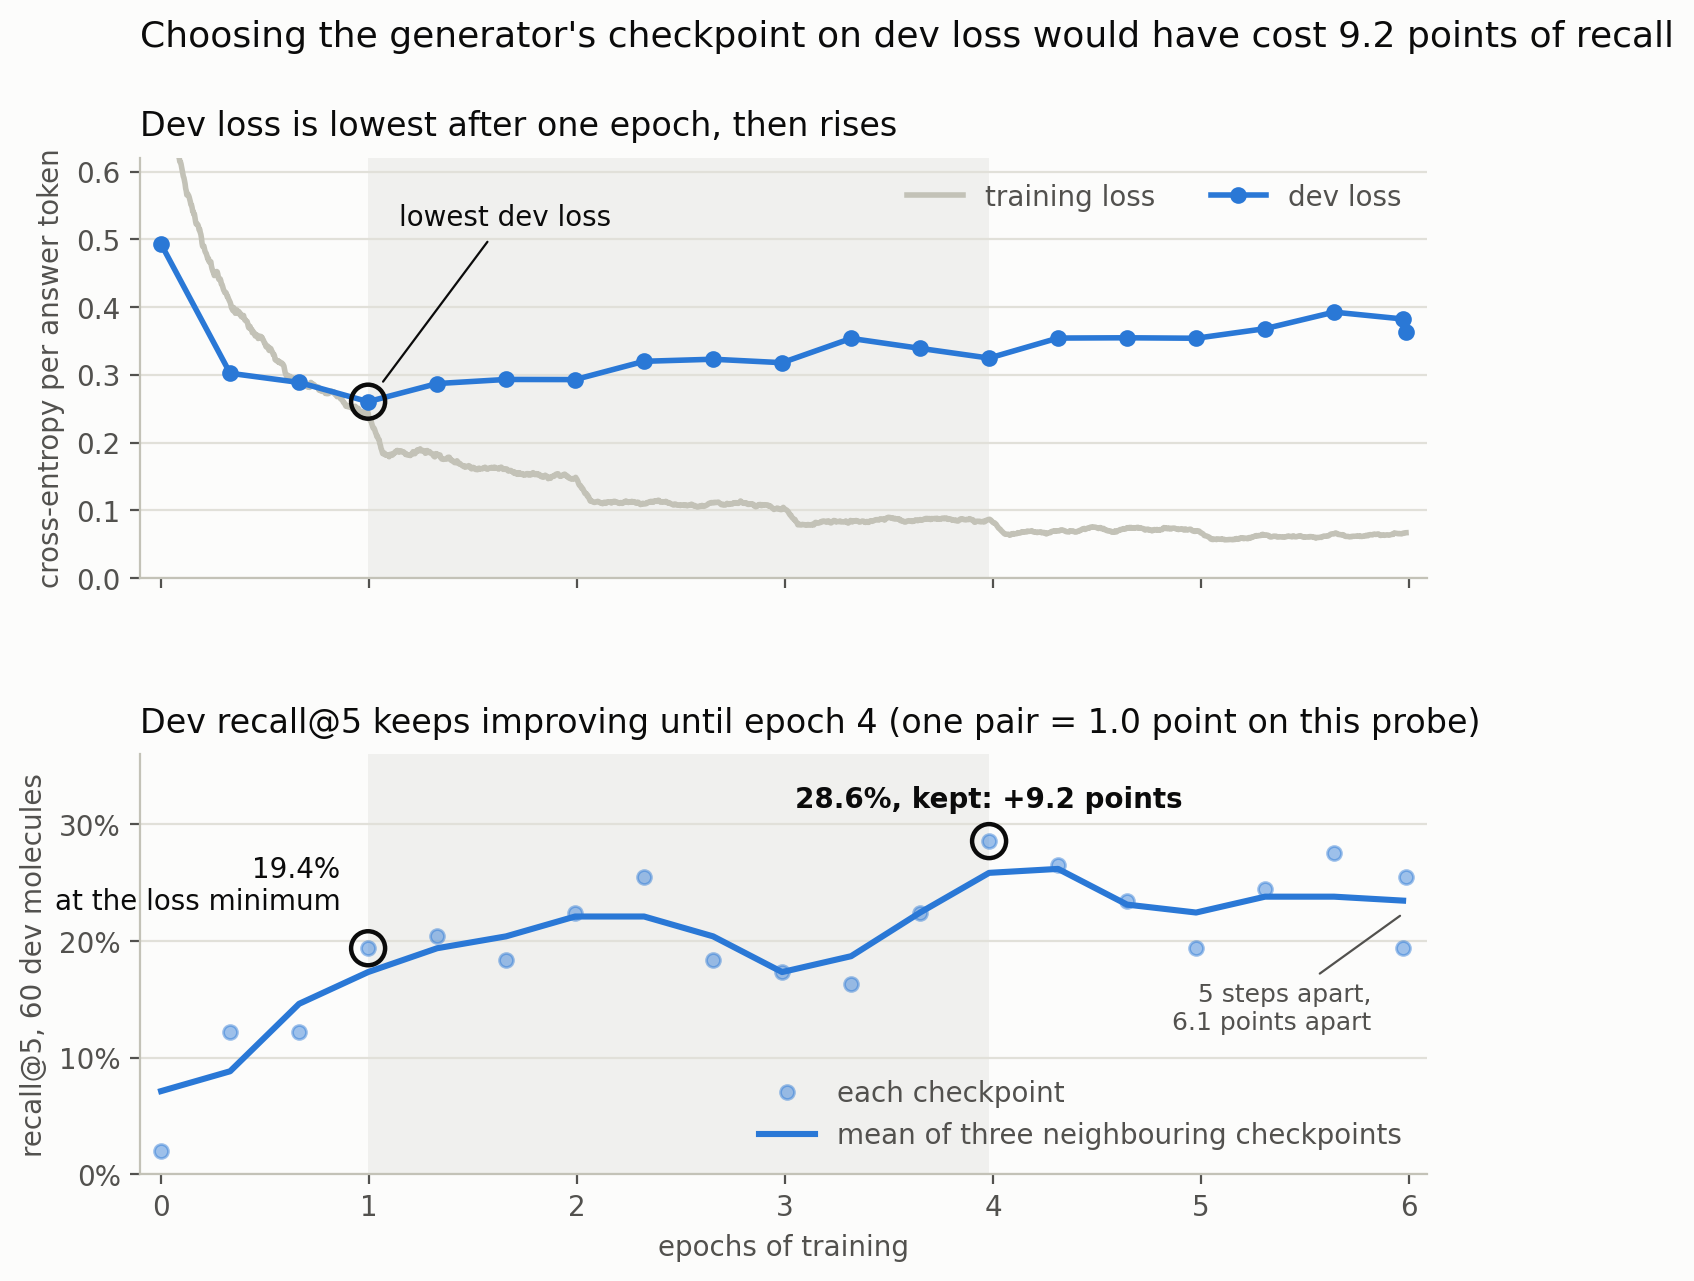

  recall@5 at the loss minimum 19.4%, at the kept checkpoint 28.6% (+9.2 points)
  three-checkpoint mean: 17.3% at the loss minimum, 26.2% at its peak

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Blue is the series the claim is about; grey is context. The same roles hold in every figure.
BLUE, GREY, LIGHT = "#2a78d6", "#898781", "#c3c2b7"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"

STEPS_PER_EPOCH = RUN["train_examples"] / RUN["batch"]
hist["epochs"] = hist["step"] / STEPS_PER_EPOCH
ev_pts = hist.dropna(subset=["dev_recall5"]).copy()
# Three-checkpoint mean: on a 98-pair probe one checkpoint can swing six points on its own. The
# extra reading five steps before the end is left out of it, so it does not bend the line.
regular = ev_pts.iloc[:-1]
regular_smooth = regular["dev_recall5"].rolling(3, center=True, min_periods=2).mean()
lo = ev_pts.loc[ev_pts["dev_loss"].idxmin()]        # where dev loss says to stop
hi = ev_pts.loc[ev_pts["dev_recall5"].idxmax()]     # the checkpoint selection kept
gain = (hi["dev_recall5"] - lo["dev_recall5"]) * 100
n_pairs = sum(len(dev_by_parent[p]) for p in dev_parents)
last2 = ev_pts.tail(2)

fig, axes = plt.subplots(2, 1, figsize=(8.3, 6.6), sharex=True, gridspec_kw={"hspace": 0.42})
fig.patch.set_facecolor(SURFACE)
for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(LIGHT)
    ax.tick_params(colors=MUTED, labelsize=10)
    ax.axvspan(lo["epochs"], hi["epochs"], color=GREY, alpha=0.10, zorder=0, linewidth=0)

ax = axes[0]
ax.plot(hist["epochs"], hist["loss"].rolling(25, min_periods=1).mean(), color=LIGHT,
        linewidth=2, label="training loss")
ax.plot(ev_pts["epochs"], ev_pts["dev_loss"], color=BLUE, linewidth=2, marker="o",
        markersize=5, label="dev loss")
ax.scatter([lo["epochs"]], [lo["dev_loss"]], s=150, facecolor="none", edgecolor=INK,
           linewidth=1.6, zorder=5)
ax.annotate("lowest dev loss", xy=(lo["epochs"], lo["dev_loss"]), xytext=(lo["epochs"] + 0.15, 0.52),
            ha="left", color=INK, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=INK, linewidth=0.8, shrinkB=9))
ax.set_ylim(0, 0.62)
ax.set_ylabel("cross-entropy per answer token", color=MUTED, fontsize=10)
ax.set_title("Dev loss is lowest after one epoch, then rises", color=INK, fontsize=11,
             loc="left", pad=8)
ax.legend(frameon=False, fontsize=10, labelcolor=MUTED, loc="upper right", ncol=2)

ax = axes[1]
ax.plot(ev_pts["epochs"], ev_pts["dev_recall5"], linestyle="none", marker="o", markersize=5,
        color=BLUE, alpha=0.45, label="each checkpoint")
ax.plot(regular["epochs"], regular_smooth, color=BLUE, linewidth=2.2,
        label="mean of three neighbouring checkpoints")
for row in (lo, hi):
    ax.scatter([row["epochs"]], [row["dev_recall5"]], s=150, facecolor="none", edgecolor=INK,
               linewidth=1.6, zorder=5)
ax.annotate(f"{lo['dev_recall5']:.1%}\nat the loss minimum", xy=(lo["epochs"], lo["dev_recall5"]),
            xytext=(9, 13), textcoords="offset points", ha="left", color=INK, fontsize=9)
ax.annotate(f"{hi['dev_recall5']:.1%}, kept: +{gain:.1f} points",
            xy=(hi["epochs"], hi["dev_recall5"]), xytext=(0, 12), textcoords="offset points",
            ha="center", color=INK, fontsize=10, fontweight="bold")
ax.annotate(f"{int(last2['step'].diff().iloc[-1])} steps apart,\n"
            f"{abs(last2['dev_recall5'].diff().iloc[-1])*100:.1f} points apart",
            xy=(last2["epochs"].mean(), last2["dev_recall5"].mean()), xytext=(-12, -42),
            textcoords="offset points", ha="right", color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.36)
ax.set_ylabel(f"recall@5, {len(dev_parents)} dev molecules", color=MUTED, fontsize=10)
ax.set_xlabel("epochs of training", color=MUTED, fontsize=10)
ax.set_title(f"Dev recall@5 keeps improving until epoch {round(hi['epochs'])} "
             f"(one pair = {100/n_pairs:.1f} point on this probe)", color=INK, fontsize=11,
             loc="left", pad=8)
ax.legend(frameon=False, fontsize=10, labelcolor=MUTED, loc="lower right")
ax.set_xlim(-0.1, hist["epochs"].max() + 0.1)

fig.suptitle("Checkpoint selection: dev loss against dev recall@5",
             color=INK, fontsize=13, fontweight="bold", x=0.125, ha="left", y=0.985)
plt.savefig(ROOT / "docs/finetune_curves.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"  recall@5 at the loss minimum {lo['dev_recall5']:.1%}, at the kept checkpoint "
      f"{hi['dev_recall5']:.1%} ({gain:+.1f} points)")
print(f"  three-checkpoint mean: {regular_smooth.loc[lo.name]:.1%} at the loss minimum, "
      f"{regular_smooth.max():.1%} at its peak")

The top panel separates learning from memorising. Training loss alone can be driven to nothing by
memorising, so the question is whether the held-out curve follows it down.

It does not. Dev loss is lowest at **step 354, the end of the first epoch**, then climbs while
training loss keeps falling. On the standard reading that is overfitting from epoch one, and the
checkpoint to keep is the one before the turn. **Recall@5 goes on improving for three more
epochs**, from 19.4% at that minimum to 28.6% at step 1416, the end of the fourth.

For this task the loss is the wrong criterion. Cross-entropy scores the probability assigned to
*one* reference string. Most parents have several true metabolites, so probability moved onto a
*different* correct metabolite counts as error, as does probability moved onto another valid
spelling of the same molecule. Recall@5 asks only whether any of five predictions matches any
reference. A model that sharpens into a confident, diverse top-5 gets better at the task while
getting worse at the loss. Dev loss is a useful diagnostic but not a selection criterion, so the
checkpoint is chosen on dev recall throughout.

**The 9.2 points are one reading against another.** The kept checkpoint is the best of 20 noisy
probe readings, so it is biased upward, and single readings swing: the last two, five steps apart,
differ by 6.1 points. The line in the bottom panel is the mean of three neighbouring checkpoints.
It rises from 17.3% at the loss minimum to 26.2% at its peak, about 9 points, so the conclusion
does not rest on one lucky reading.

The first point, at epoch 0, comes after the 20-step smoke run. The
untuned model on the same probe and decoder has dev loss 1.496 and recall 0.0%, off the scale of
both panels. Unreadable replies and parent echoes both collapse inside the first epoch.

**Probe resolution.** 60 molecules carry 98 pairs, so one pair moves the probe by about a point
and differences of a few points are not measurable. The probe is used to *choose* between
checkpoints, where a noisy comparison is tolerable because the alternative is guessing an epoch
count. It is never used to report.

## 6. The checkpoint, and what it scores

The checkpoint with the best dev recall, scored on the full dev set.

In [8]:
margin = policy["recall5"] - untuned["recall5"]
summary = pd.DataFrame([{
    "model": BASE_MODEL,
    "training examples": len(train_rows),
    "epochs": EPOCHS,
    "optimizer updates": step + SMOKE_STEPS,
    "batch / learning rate": f"{BATCH} / {LR}",
    "best checkpoint at step": best["step"],
    f"probe recall@5 ({len(dev_parents)} molecules, selected on)": f"{best['recall']:.1%}",
    f"unseen recall@5 ({len(unseen_parents)} molecules, never probed)": f"{unseen['recall5']:.1%}",
    f"REPORTED recall@5 (all {len(all_dev_parents)}, real decoder)": f"{policy['recall5']:.1%}",
    "reported recall@1": f"{policy['recall1']:.1%}",
    "share of the metric ceiling": f"{policy['pct_of_ceiling5']:.0%}",
    "untuned, same probe and prompt": f"{untuned['recall5']:.1%}",
    "moved by fine-tuning": f"{margin*100:+.1f}pp",
    "dev loss, untuned -> final": f"{untuned['dev_loss']:.3f} -> {RUN['final_dev_loss']:.3f}",
}]).T.rename(columns={0: "run A"})
summary

,run A
model,Qwen/Qwen3-8B
training examples,17075
epochs,6
optimizer updates,2150
batch / learning rate,48 / 0.0001
best checkpoint at step,1416
"probe recall@5 (60 molecules, selected on)",28.6%
"unseen recall@5 (190 molecules, never probed)",25.1%
"REPORTED recall@5 (all 250, real decoder)",29.3%
reported recall@1,16.0%


The trained weights are at the `tinker://` path recorded in `data/processed/finetune_run.json`,
saved with a seven-day TTL. Arms 3, 4 and 5 in notebook 04 read that file,
so they run from a cold kernel without retraining.

The probe figure is what the checkpoint was *selected* on: 60 molecules, measured about 18 times
across the run, so the maximum of many noisy reads is biased upward. The full-dev figure is the
one to quote.